In [236]:
import pandas  as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [237]:
plt.style.use('seaborn-v0_8-whitegrid')

In [238]:
df = pd.read_csv('Brazillian_cleaned_olist_dataset.csv')
df

,order_id,payment_sequence_no,payment_type,payment_installments,payment_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code,customer_city,customer_state
0,b81ef226f3fe1789b1e8b2acac839d17,1,Credit_Card,8,99.33,0a8556ac6be836b46b3e89920d59291c,Delivered,2018-04-25 22:01:49,2018-04-25 22:15:09,2018-05-02 15:20:00,2018-05-09 17:36:51,2018-05-22,708ab75d2a007f0564aedd11139c7708,39801,Teofilo Otoni,MG
1,a9810da82917af2d9aefd1278f1dcfa0,1,Credit_Card,1,24.39,f2c7fc58a9de810828715166c672f10a,Delivered,2018-06-26 11:01:38,2018-06-26 11:18:58,2018-06-28 14:18:00,2018-06-29 20:32:09,2018-07-16,a8b9d3a27068454b1c98cc67d4e31e6f,2422,Sao Paulo,SP
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,Credit_Card,1,65.71,25b14b69de0b6e184ae6fe2755e478f9,Delivered,2017-12-12 11:19:55,2017-12-14 09:52:34,2017-12-15 20:13:22,2017-12-18 17:24:41,2018-01-04,6f70c0b2f7552832ba46eb57b1c5651e,2652,Sao Paulo,SP
3,ba78997921bbcdc1373bb41e913ab953,1,Credit_Card,8,107.78,7a5d8efaaa1081f800628c30d2b0728f,Delivered,2017-12-06 12:04:06,2017-12-06 12:13:20,2017-12-07 20:28:28,2017-12-21 01:35:51,2018-01-04,87695ed086ebd36f20404c82d20fca87,36060,Juiz De Fora,MG
4,42fdf880ba16b47b59251dd489d4441a,1,Credit_Card,2,128.45,15fd6fb8f8312dbb4674e4518d6fa3b3,Delivered,2018-05-21 13:59:17,2018-05-21 16:14:41,2018-05-22 11:46:00,2018-06-01 21:44:53,2018-06-13,4291db0da71914754618cd789aebcd56,18570,Conchas,SP
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
103872,0406037ad97740d563a178ecc7a2075c,1,Boleto,1,363.31,5d576cb2dfa3bc05612c392a1ee9c654,Delivered,2018-03-08 16:57:23,2018-03-10 03:55:25,2018-03-12 18:19:36,2018-03-16 13:09:51,2018-04-04,b6027ac07fb76ebca8c97b1887865aee,12954,Atibaia,SP
103873,7b905861d7c825891d6347454ea7863f,1,Credit_Card,2,96.80,2079230c765a88530822a34a4cec2aa0,Delivered,2017-08-18 09:45:35,2017-08-18 10:04:56,2017-08-18 18:04:24,2017-08-23 22:25:56,2017-09-12,53b30ca78efb2b7efcd3f9e461587eb2,30210,Belo Horizonte,MG
103874,32609bbb3dd69b3c066a6860554a77bf,1,Credit_Card,1,47.77,e4abb5057ec8cfda9759c0dc415a8188,Invoiced,2017-11-18 17:27:14,2017-11-18 17:46:05,NaN,NaN,2017-12-05,d3c7da954a324253814096bcaf240e4e,1519,Sao Paulo,SP
103875,b8b61059626efa996a60be9bb9320e10,1,Credit_Card,5,369.54,5d719b0d300663188169c6560e243f27,Delivered,2018-08-07 23:26:13,2018-08-07 23:45:00,2018-08-09 11:46:00,2018-08-21 22:41:46,2018-08-24,b84dc68f02f122a88d7e7bbd37b06204,22733,Rio De Janeiro,RJ


In [239]:
df.head()

,order_id,payment_sequence_no,payment_type,payment_installments,payment_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code,customer_city,customer_state
0,b81ef226f3fe1789b1e8b2acac839d17,1,Credit_Card,8,99.33,0a8556ac6be836b46b3e89920d59291c,Delivered,2018-04-25 22:01:49,2018-04-25 22:15:09,2018-05-02 15:20:00,2018-05-09 17:36:51,2018-05-22,708ab75d2a007f0564aedd11139c7708,39801,Teofilo Otoni,MG
1,a9810da82917af2d9aefd1278f1dcfa0,1,Credit_Card,1,24.39,f2c7fc58a9de810828715166c672f10a,Delivered,2018-06-26 11:01:38,2018-06-26 11:18:58,2018-06-28 14:18:00,2018-06-29 20:32:09,2018-07-16,a8b9d3a27068454b1c98cc67d4e31e6f,2422,Sao Paulo,SP
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,Credit_Card,1,65.71,25b14b69de0b6e184ae6fe2755e478f9,Delivered,2017-12-12 11:19:55,2017-12-14 09:52:34,2017-12-15 20:13:22,2017-12-18 17:24:41,2018-01-04,6f70c0b2f7552832ba46eb57b1c5651e,2652,Sao Paulo,SP
3,ba78997921bbcdc1373bb41e913ab953,1,Credit_Card,8,107.78,7a5d8efaaa1081f800628c30d2b0728f,Delivered,2017-12-06 12:04:06,2017-12-06 12:13:20,2017-12-07 20:28:28,2017-12-21 01:35:51,2018-01-04,87695ed086ebd36f20404c82d20fca87,36060,Juiz De Fora,MG
4,42fdf880ba16b47b59251dd489d4441a,1,Credit_Card,2,128.45,15fd6fb8f8312dbb4674e4518d6fa3b3,Delivered,2018-05-21 13:59:17,2018-05-21 16:14:41,2018-05-22 11:46:00,2018-06-01 21:44:53,2018-06-13,4291db0da71914754618cd789aebcd56,18570,Conchas,SP


In [240]:
df.tail()

,order_id,payment_sequence_no,payment_type,payment_installments,payment_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code,customer_city,customer_state
103872,0406037ad97740d563a178ecc7a2075c,1,Boleto,1,363.31,5d576cb2dfa3bc05612c392a1ee9c654,Delivered,2018-03-08 16:57:23,2018-03-10 03:55:25,2018-03-12 18:19:36,2018-03-16 13:09:51,2018-04-04,b6027ac07fb76ebca8c97b1887865aee,12954,Atibaia,SP
103873,7b905861d7c825891d6347454ea7863f,1,Credit_Card,2,96.80,2079230c765a88530822a34a4cec2aa0,Delivered,2017-08-18 09:45:35,2017-08-18 10:04:56,2017-08-18 18:04:24,2017-08-23 22:25:56,2017-09-12,53b30ca78efb2b7efcd3f9e461587eb2,30210,Belo Horizonte,MG
103874,32609bbb3dd69b3c066a6860554a77bf,1,Credit_Card,1,47.77,e4abb5057ec8cfda9759c0dc415a8188,Invoiced,2017-11-18 17:27:14,2017-11-18 17:46:05,NaN,NaN,2017-12-05,d3c7da954a324253814096bcaf240e4e,1519,Sao Paulo,SP
103875,b8b61059626efa996a60be9bb9320e10,1,Credit_Card,5,369.54,5d719b0d300663188169c6560e243f27,Delivered,2018-08-07 23:26:13,2018-08-07 23:45:00,2018-08-09 11:46:00,2018-08-21 22:41:46,2018-08-24,b84dc68f02f122a88d7e7bbd37b06204,22733,Rio De Janeiro,RJ
103876,28bbae6599b09d39ca406b747b6632b1,1,Boleto,1,191.58,4c7f868f43b5cff577b0becb8c8b7860,Delivered,2017-12-05 08:18:35,2017-12-06 02:50:09,2017-12-08 00:51:47,2018-02-05 14:59:09,2017-12-29,b1f51a4e19da3338e51fbcfabefad1bf,23059,Rio De Janeiro,RJ


In [241]:
df.shape

(103877, 16)

In [242]:
print("the number of rows present in the dataset are : ",df.shape[0])

the number of rows present in the dataset are :  103877


In [243]:
print("the number of columns present in the dataset are : ",df.shape[1])

the number of columns present in the dataset are :  16


In [244]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 103877 entries, 0 to 103876
Data columns (total 16 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   order_id                       103877 non-null  str    
 1   payment_sequence_no            103877 non-null  int64  
 2   payment_type                   103877 non-null  str    
 3   payment_installments           103877 non-null  int64  
 4   payment_value                  103877 non-null  float64
 5   customer_id                    103877 non-null  str    
 6   order_status                   103877 non-null  str    
 7   order_purchase_timestamp       103877 non-null  str    
 8   order_approved_at              103877 non-null  str    
 9   order_delivered_carrier_date   101992 non-null  str    
 10  order_delivered_customer_date  100750 non-null  str    
 11  order_estimated_delivery_date  103877 non-null  str    
 12  customer_unique_id             103877 non

In [245]:
df.describe(include = 'number').round(2)

,payment_sequence_no,payment_installments,payment_value,customer_zip_code
count,103877.00,103877.00,103877.00,103877.00
mean,1.09,2.85,154.11,35072.50
std,0.70,2.69,217.50,29743.42
min,1.00,0.00,0.01,1003.00
25%,1.00,1.00,56.82,11370.00
50%,1.00,1.00,100.00,24360.00
75%,1.00,4.00,171.84,58418.00
max,29.00,24.00,13664.08,99990.00


## FEATURE ENGINEERING

> **Note on Data Types:** 
> Exporting the cleaned dataset to CSV saves date values as plain strings (text). Upon reloading the dataset for EDA/Feature Engineering, date columns need to be re-converted to `datetime64` data type for time-based feature extraction.

In [246]:
date_cols = ['order_purchase_timestamp', 'order_approved_at',
       'order_delivered_carrier_date', 'order_delivered_customer_date',
       'order_estimated_delivery_date']

for i in date_cols:
    df[i] = pd.to_datetime(df[i])

In [247]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 103877 entries, 0 to 103876
Data columns (total 16 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   order_id                       103877 non-null  str           
 1   payment_sequence_no            103877 non-null  int64         
 2   payment_type                   103877 non-null  str           
 3   payment_installments           103877 non-null  int64         
 4   payment_value                  103877 non-null  float64       
 5   customer_id                    103877 non-null  str           
 6   order_status                   103877 non-null  str           
 7   order_purchase_timestamp       103877 non-null  datetime64[us]
 8   order_approved_at              103877 non-null  datetime64[us]
 9   order_delivered_carrier_date   101992 non-null  datetime64[us]
 10  order_delivered_customer_date  100750 non-null  datetime64[us]
 11  order_estim

In [248]:
# Measuring total days taken from purchase to delivery.


df['delivery_time_days'] = (df['order_delivered_customer_date'] - df['order_purchase_timestamp']).dt.days

In [249]:
df['delivery_time_days'].head()

0    13.0
1     3.0
2     6.0
3    14.0
4    11.0
Name: delivery_time_days, dtype: float64

In [250]:
# Calculating the difference between actual delivery date and estimated delivery date, where negative values indicate a late delivery.

df['delivery_delay_days'] = (df['order_estimated_delivery_date'] - df['order_delivered_customer_date']).dt.days

In [251]:
df['delivery_delay_days']

0         12.0
1         16.0
2         16.0
3         13.0
4         11.0
          ... 
103872    18.0
103873    19.0
103874     NaN
103875     2.0
103876   -39.0
Name: delivery_delay_days, Length: 103877, dtype: float64

In [252]:
# A binary indicator flag where 1 represents a late delivery and 0 represents an on-time or early delivery.

df['is_late'] = (df['delivery_delay_days'] < 0).astype(int)   

In [253]:
df['is_late'].head()

0    0
1    0
2    0
3    0
4    0
Name: is_late, dtype: int64

In [254]:
#Extracting discrete Time Units from the purchase timestamp to analyze Year trend patterns.

df['purchase_year'] = df['order_purchase_timestamp'].dt.year

In [255]:
df['purchase_year'].head()

0    2018
1    2018
2    2017
3    2017
4    2018
Name: purchase_year, dtype: int32

In [256]:
#Extracting discrete Time Units from the purchase timestamp to analyze Month trend patterns.  

df['month'] = df['order_purchase_timestamp'].dt.month_name()

In [257]:
df['month'].head()

0       April
1        June
2    December
3    December
4         May
Name: month, dtype: str

In [258]:
#Extracting discrete Time Units from the purchase timestamp to analyze Day trend patterns.  
  
df['day'] = df['order_purchase_timestamp'].dt.day_name()

In [259]:
df['day'].head()

0    Wednesday
1      Tuesday
2      Tuesday
3    Wednesday
4       Monday
Name: day, dtype: str

In [260]:
# Calculating the average monetary amount to be paid per EMI installment for a particular order.

df['avg_emi_amount'] = (df['payment_value'] / df['payment_installments'].replace(0,1)).round(2)

In [261]:
df['avg_emi_amount'].head()

0    12.42
1    24.39
2    65.71
3    13.47
4    64.22
Name: avg_emi_amount, dtype: float64

In [262]:
# Measures the duration in hours between order placement and payment confirmation to detect payment delays.

df['approval_time_hours'] = ((df['order_approved_at'] - df['order_purchase_timestamp']).dt.total_seconds() / 3600).round(2)

In [263]:
df['approval_time_hours'].head()

0     0.22
1     0.29
2    46.54
3     0.15
4     2.26
Name: approval_time_hours, dtype: float64

In [264]:
# Calculating the purchase_hour to analyze the time of day when most purchases are made.
df['purchase_hour'] = (df['order_purchase_timestamp'].dt.hour).astype(int)

In [265]:
df['purchase_hour'].head()

0    22
1    11
2    11
3    12
4    13
Name: purchase_hour, dtype: int64

## DATA ANALYSIS

In [266]:
df

,order_id,payment_sequence_no,payment_type,payment_installments,payment_value,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,...,customer_state,delivery_time_days,delivery_delay_days,is_late,purchase_year,month,day,avg_emi_amount,approval_time_hours,purchase_hour
0,b81ef226f3fe1789b1e8b2acac839d17,1,Credit_Card,8,99.33,0a8556ac6be836b46b3e89920d59291c,Delivered,2018-04-25 22:01:49,2018-04-25 22:15:09,2018-05-02 15:20:00,...,MG,13.0,12.0,0,2018,April,Wednesday,12.42,0.22,22
1,a9810da82917af2d9aefd1278f1dcfa0,1,Credit_Card,1,24.39,f2c7fc58a9de810828715166c672f10a,Delivered,2018-06-26 11:01:38,2018-06-26 11:18:58,2018-06-28 14:18:00,...,SP,3.0,16.0,0,2018,June,Tuesday,24.39,0.29,11
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,Credit_Card,1,65.71,25b14b69de0b6e184ae6fe2755e478f9,Delivered,2017-12-12 11:19:55,2017-12-14 09:52:34,2017-12-15 20:13:22,...,SP,6.0,16.0,0,2017,December,Tuesday,65.71,46.54,11
3,ba78997921bbcdc1373bb41e913ab953,1,Credit_Card,8,107.78,7a5d8efaaa1081f800628c30d2b0728f,Delivered,2017-12-06 12:04:06,2017-12-06 12:13:20,2017-12-07 20:28:28,...,MG,14.0,13.0,0,2017,December,Wednesday,13.47,0.15,12
4,42fdf880ba16b47b59251dd489d4441a,1,Credit_Card,2,128.45,15fd6fb8f8312dbb4674e4518d6fa3b3,Delivered,2018-05-21 13:59:17,2018-05-21 16:14:41,2018-05-22 11:46:00,...,SP,11.0,11.0,0,2018,May,Monday,64.22,2.26,13
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
103872,0406037ad97740d563a178ecc7a2075c,1,Boleto,1,363.31,5d576cb2dfa3bc05612c392a1ee9c654,Delivered,2018-03-08 16:57:23,2018-03-10 03:55:25,2018-03-12 18:19:36,...,SP,7.0,18.0,0,2018,March,Thursday,363.31,34.97,16
103873,7b905861d7c825891d6347454ea7863f,1,Credit_Card,2,96.80,2079230c765a88530822a34a4cec2aa0,Delivered,2017-08-18 09:45:35,2017-08-18 10:04:56,2017-08-18 18:04:24,...,MG,5.0,19.0,0,2017,August,Friday,48.40,0.32,9
103874,32609bbb3dd69b3c066a6860554a77bf,1,Credit_Card,1,47.77,e4abb5057ec8cfda9759c0dc415a8188,Invoiced,2017-11-18 17:27:14,2017-11-18 17:46:05,NaT,...,SP,NaN,NaN,0,2017,November,Saturday,47.77,0.31,17
103875,b8b61059626efa996a60be9bb9320e10,1,Credit_Card,5,369.54,5d719b0d300663188169c6560e243f27,Delivered,2018-08-07 23:26:13,2018-08-07 23:45:00,2018-08-09 11:46:00,...,RJ,13.0,2.0,0,2018,August,Tuesday,73.91,0.31,23


In [267]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 103877 entries, 0 to 103876
Data columns (total 25 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   order_id                       103877 non-null  str           
 1   payment_sequence_no            103877 non-null  int64         
 2   payment_type                   103877 non-null  str           
 3   payment_installments           103877 non-null  int64         
 4   payment_value                  103877 non-null  float64       
 5   customer_id                    103877 non-null  str           
 6   order_status                   103877 non-null  str           
 7   order_purchase_timestamp       103877 non-null  datetime64[us]
 8   order_approved_at              103877 non-null  datetime64[us]
 9   order_delivered_carrier_date   101992 non-null  datetime64[us]
 10  order_delivered_customer_date  100750 non-null  datetime64[us]
 11  order_estim

#### 1) Univariate Analysis

In [268]:
df.describe(include= 'number').round(2).T

,count,mean,std,min,25%,50%,75%,max
payment_sequence_no,103877.0,1.09,0.70,1.00,1.00,1.00,1.00,29.00
payment_installments,103877.0,2.85,2.69,0.00,1.00,1.00,4.00,24.00
payment_value,103877.0,154.11,217.50,0.01,56.82,100.00,171.84,13664.08
customer_zip_code,103877.0,35072.50,29743.42,1003.00,11370.00,24360.00,58418.00,99990.00
delivery_time_days,100750.0,12.11,9.56,0.00,6.00,10.00,15.00,209.00
delivery_delay_days,100750.0,10.89,10.19,-189.00,6.00,11.00,16.00,146.00
is_late,103877.0,0.08,0.27,0.00,0.00,0.00,0.00,1.00
purchase_year,103877.0,2017.54,0.51,2016.00,2017.00,2018.00,2018.00,2018.00
avg_emi_amount,103877.0,79.58,134.70,0.01,26.52,51.35,89.94,13664.08
approval_time_hours,103877.0,10.31,25.75,0.00,0.21,0.34,14.25,4509.18


In [269]:
# ADDING THE STATISTICAL METRICS SUCH AS Median ,Skewness and Iqr for the numerical columns in the dataset. 

numerical_cols = ['payment_sequence_no', 'payment_installments', 'payment_value',
       'customer_zip_code', 'delivery_time_days', 'delivery_delay_days',
       'is_late', 'purchase_year', 'avg_emi_amount', 'approval_time_hours',
       'purchase_hour']

numeric_summary = df[numerical_cols].describe(include = 'number').T
numeric_summary['median'] = df[numerical_cols].median()
numeric_summary['skewness'] = df[numerical_cols].skew()
numeric_summary['IQR'] = numeric_summary['75%'] - numeric_summary['25%']
print("THE SUMMARY STATISTICS OF THE NUMERICAL COLUMNS IS : \n")
numeric_summary = numeric_summary[['count', 'mean', 'std', 'median', 'IQR', 'min', 'max', 'skewness']].round(2)
numeric_summary.T

THE SUMMARY STATISTICS OF THE NUMERICAL COLUMNS IS : 



,payment_sequence_no,payment_installments,payment_value,customer_zip_code,delivery_time_days,delivery_delay_days,is_late,purchase_year,avg_emi_amount,approval_time_hours,purchase_hour
count,103877.00,103877.00,103877.00,103877.00,100750.00,100750.00,103877.00,103877.00,103877.00,103877.00,103877.00
mean,1.09,2.85,154.11,35072.50,12.11,10.89,0.08,2017.54,79.58,10.31,14.78
std,0.70,2.69,217.50,29743.42,9.56,10.19,0.27,0.51,134.70,25.75,5.34
median,1.00,1.00,100.00,24360.00,10.00,11.00,0.00,2018.00,51.35,0.34,15.00
IQR,0.00,3.00,115.02,47048.00,9.00,10.00,0.00,1.00,63.42,14.04,8.00
min,1.00,0.00,0.01,1003.00,0.00,-189.00,0.00,2016.00,0.01,0.00,0.00
max,29.00,24.00,13664.08,99990.00,209.00,146.00,1.00,2018.00,13664.08,4509.18,23.00
skewness,16.23,1.65,9.25,0.78,3.82,-2.03,3.14,-0.22,21.72,56.34,-0.61


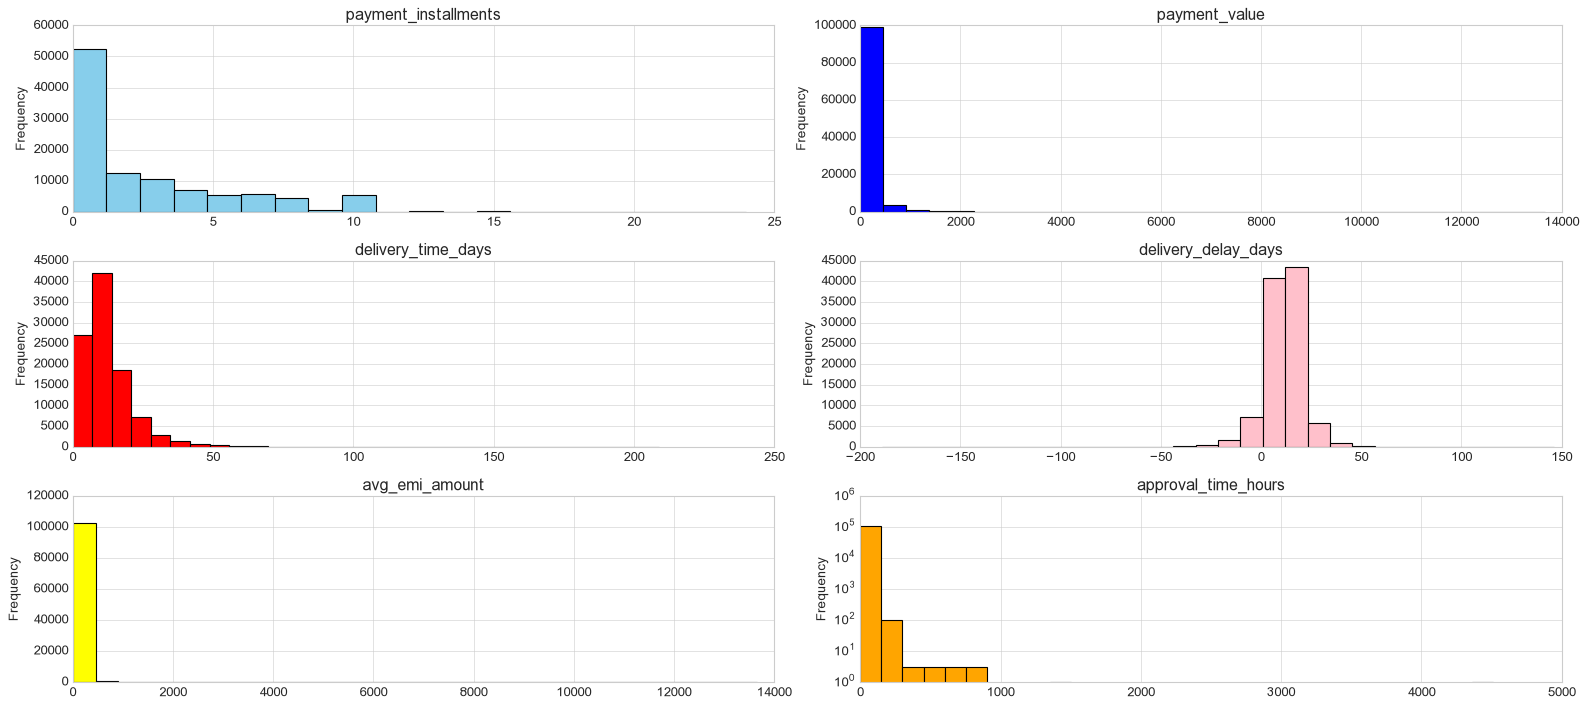

In [270]:
# PLOTTING THE HISTOGRAM FOR THE NUMERICAL COLUMNS IN THE DATASET TO VISUALIZE THE DISTRIBUTION OF THE DATA.
#NUMERICAL
fig, ax = plt.subplots(nrows=3, ncols=2, figsize=(20, 9))
df['payment_installments'].plot(kind='hist',title = 'payment_installments',color='skyblue', edgecolor='black',ax=ax[0, 0],bins=20)
df['payment_value'].plot(kind='hist',title = 'payment_value',color='blue', edgecolor='black',ax=ax[0, 1],bins=30)
df['delivery_time_days'].plot(kind='hist',title = 'delivery_time_days', color='red', edgecolor='black', ax=ax[1, 0],bins=30)
df['delivery_delay_days'].plot(kind='hist',title = 'delivery_delay_days', color='pink', edgecolor='black', ax=ax[1, 1],bins=30)
df['avg_emi_amount'].plot(kind='hist',title = 'avg_emi_amount', color='yellow', edgecolor='black', ax=ax[2, 0],bins=30)
df['approval_time_hours'].plot(kind='hist',title = 'approval_time_hours', color='orange', edgecolor='black', ax=ax[2, 1],bins=30,log = True)
plt.tight_layout()
plt.show()

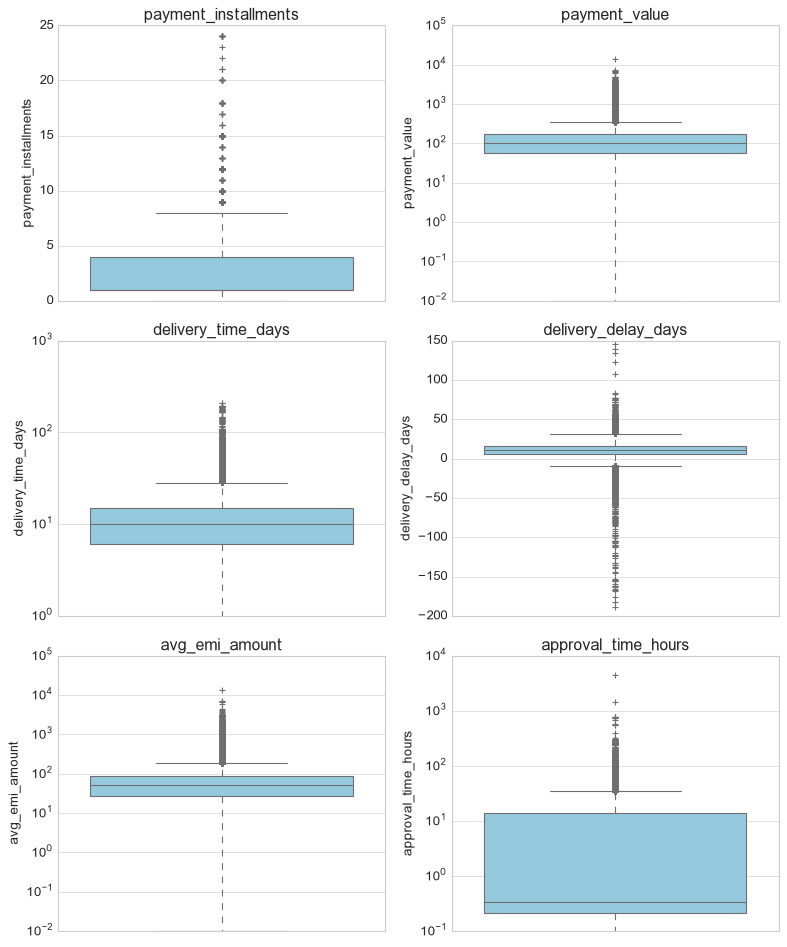

In [271]:
# PLOTTING THE BOXPLOT FOR THE NUMERICAL COLUMNS IN THE DATASET TO VISUALIZE THE DISTRIBUTION OF THE DATA.
#NUMERICAL
fig, ax = plt.subplots(nrows=3, ncols=2, figsize=(10, 12))
sns.boxplot(y=df['payment_installments'], ax=ax[0, 0], color='skyblue').set_title('payment_installments')
sns.boxplot(y=df['payment_value'], ax=ax[0, 1], color='skyblue').set(yscale="log", title='payment_value')
sns.boxplot(y=df['delivery_time_days'], ax=ax[1, 0], color='skyblue').set(yscale="log", title='delivery_time_days')
sns.boxplot(y=df['delivery_delay_days'], ax=ax[1, 1], color='skyblue').set_title('delivery_delay_days')
sns.boxplot(y=df['avg_emi_amount'], ax=ax[2, 0], color='skyblue').set(yscale="log", title='avg_emi_amount')
sns.boxplot(y=df['approval_time_hours'], ax=ax[2, 1], color='skyblue').set(yscale="log", title='approval_time_hours')
plt.tight_layout()
plt.show()

Frequency counnts for order_status : 
 order_status
Delivered      100752
Shipped          1164
Cancelled         661
Unavailable       649
Invoiced          325
Processing        319
Created             5
Approved            2
Name: count, dtype: int64


Frequency counnts for payment_type : 
 payment_type
Credit_Card    76795
Boleto         19784
Voucher         5769
Debit_Card      1529
Name: count, dtype: int64


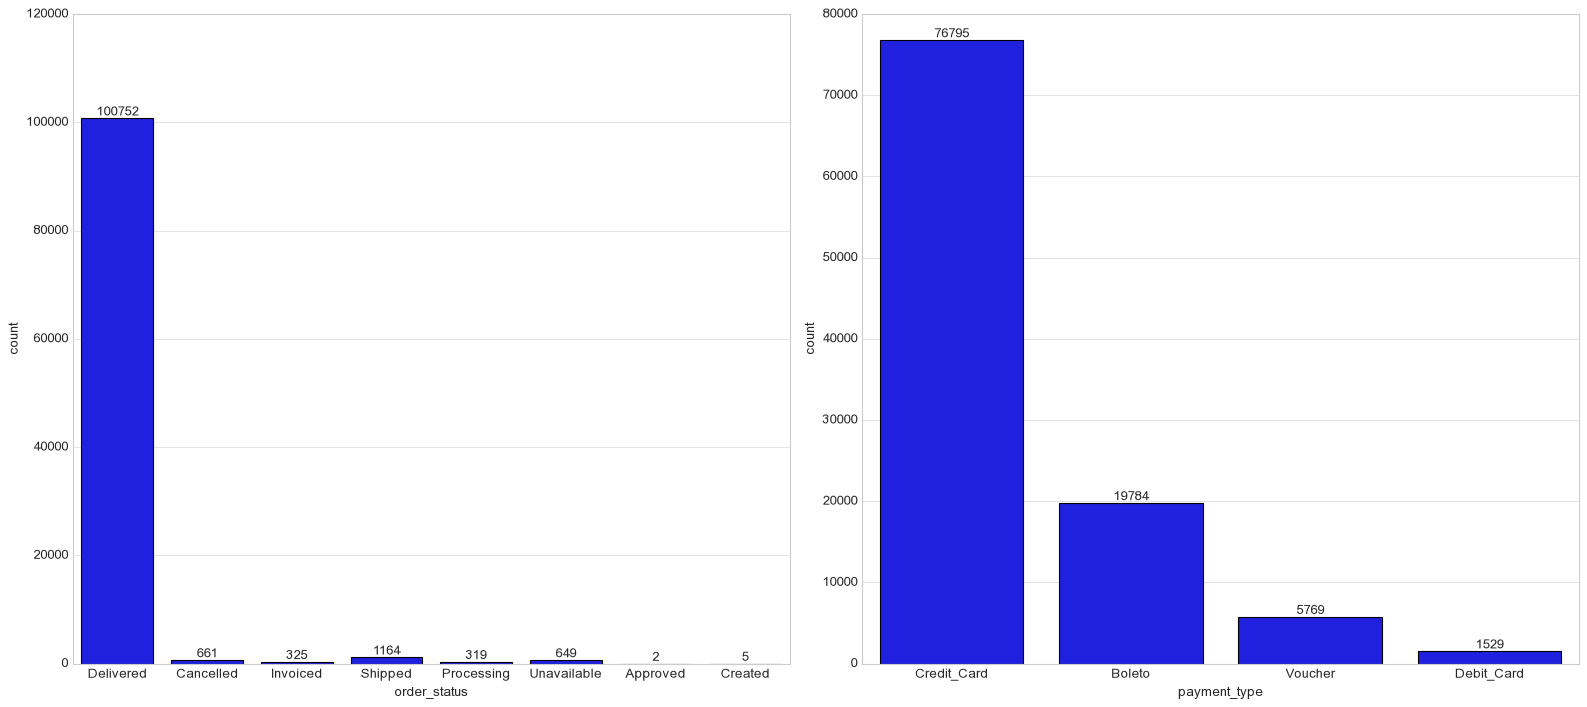

In [272]:
# PLOTTING THE BAR CHART FOR THE CATEGORICAL COLUMNS IN THE DATASET TO VISUALIZE THE DISTRIBUTION OF THE DATA.
# CATEGORICAL

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(20, 9))
print("Frequency counnts for order_status : \n",df['order_status'].value_counts())
sns.countplot(data=df,x = df['order_status'],ax=ax[0])
ax[0].bar_label(ax[0].containers[0])
print("\n\nFrequency counnts for payment_type : \n",df['payment_type'].value_counts())
sns.countplot(data=df,x = df['payment_type'],ax=ax[1])
ax[1].bar_label(ax[1].containers[0])
plt.tight_layout()
plt.show()

In [273]:
print("THE TOTAL NUMBER OF UNIQUE ORDERS PLACED IN EACH YEAR IS : ",df['order_id'].nunique())

THE TOTAL NUMBER OF UNIQUE ORDERS PLACED IN EACH YEAR IS :  99437


NUMBER OF ORDERS PER YEAR : 
     purchase_year  order_id
0           2016       328
1           2017     45101
2           2018     54008


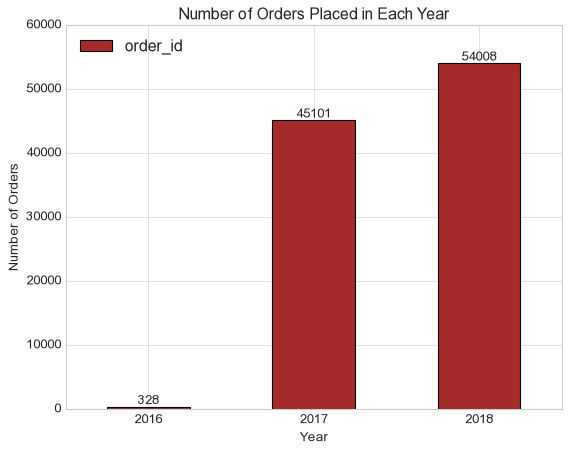

In [274]:
# PLOTTING A BAR CHART TO VISUALIZE THE NUMBER OF UNIQUE ORDERS PLACED IN EACH YEAR -- YEARLY DISTRIBUTION
# TIME-SERIES PLOTS
p = df.groupby('purchase_year')['order_id'].nunique().reset_index()
ax = p.plot(kind='bar', x='purchase_year', y='order_id', title='Number of Orders Placed in Each Year', xlabel='Year', ylabel='Number of Orders', color=['brown'])
ax.bar_label(ax.containers[0])
print("NUMBER OF ORDERS PER YEAR : \n ",p)
plt.xticks(rotation=0)
plt.show()


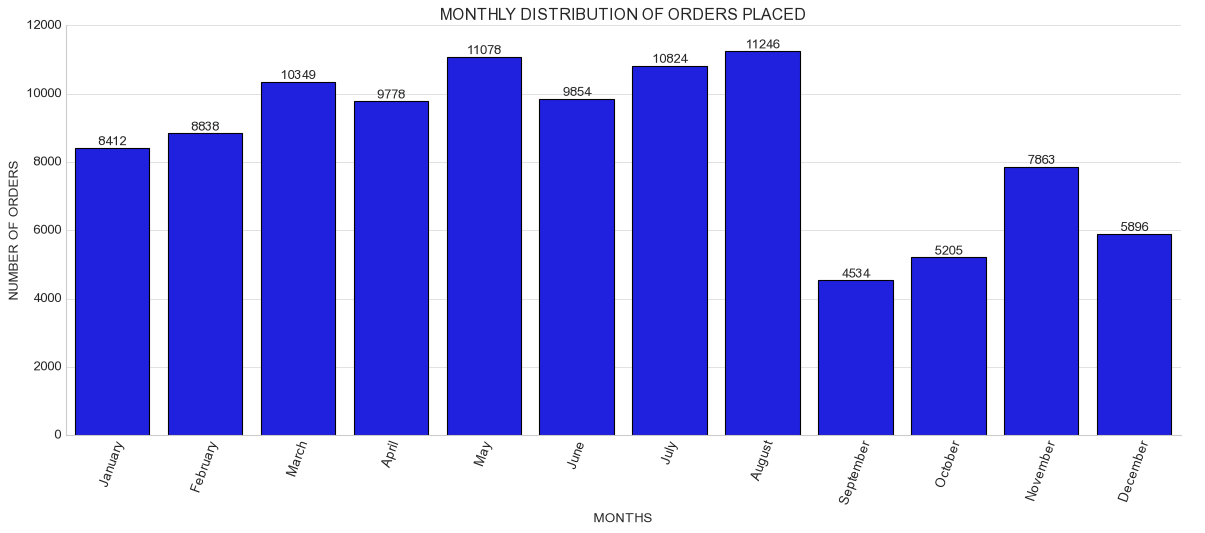

In [275]:
# MONTHLY DISTRIBUTION OF ORDERS PLACED

month_order = ['January','February','March','April','May','June','July','August','September','October','November','December']
g = sns.catplot(x='month', kind='count', order=month_order, data=df, height=6, aspect=15/6)
g.ax.bar_label(g.ax.containers[0])
plt.xticks(rotation=70)
plt.title('MONTHLY DISTRIBUTION OF ORDERS PLACED')
plt.xlabel('MONTHS', fontsize=12)
plt.ylabel('NUMBER OF ORDERS', fontsize=12)
plt.show()

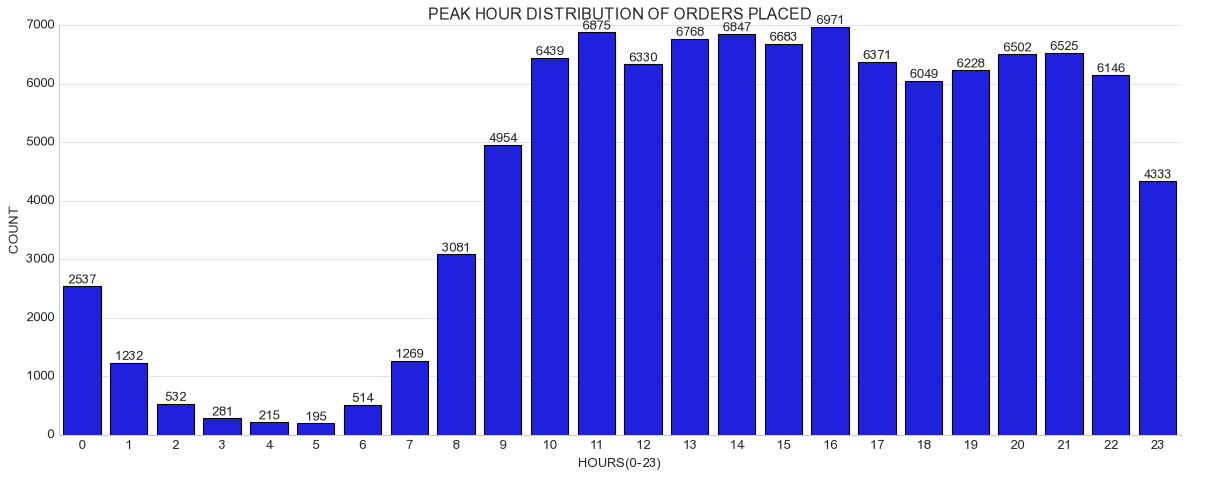

In [276]:
# PEAK HOUR DISTRIBUTION OF ORDERS PLACEED IN EACH HOUR 

ax = sns.catplot(x = df['purchase_hour'],kind = 'count',data  = df,color = 'blue', height=6, aspect=15/6)
ax.ax.bar_label(ax.ax.containers[0])
plt.title('PEAK HOUR DISTRIBUTION OF ORDERS PLACED')
plt.xlabel('HOURS(0-23)')
plt.ylabel('COUNT')
plt.show()

customer_state
SP    41742
RJ    12852
MG    11635
RS     5466
PR     5045
SC     3637
BA     3380
DF     2140
ES     2033
GO     2020
Name: order_id, dtype: int64


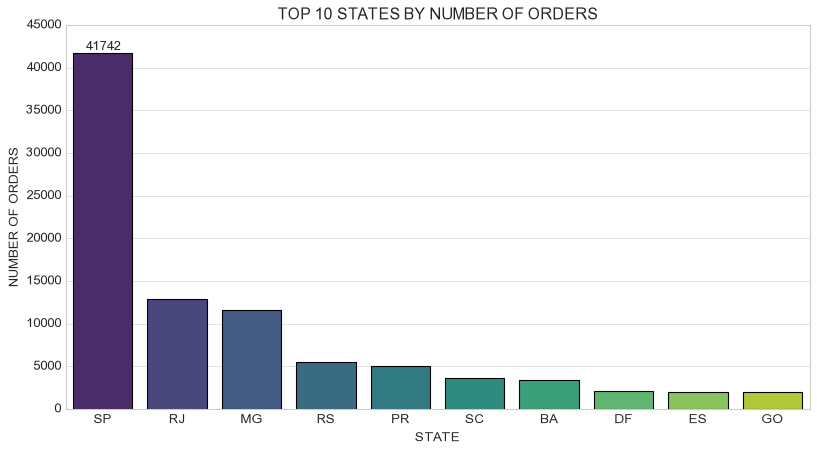

In [277]:
# VISUALIZING THE TOP 10 CUSTOMER STATES BY NUMBER OF UNIQUE ORDERS WITH THE HELP OF BARPLOT
top_states = df.groupby('customer_state')['order_id'].nunique().sort_values(ascending=False).head(10)
print(top_states)
plt.figure(figsize=(12,6))
ax = sns.barplot(x=top_states.index, y=top_states.values, palette='viridis')
ax.bar_label(ax.containers[0])
plt.title('TOP 10 STATES BY NUMBER OF ORDERS')
plt.xlabel('STATE')
plt.ylabel('NUMBER OF ORDERS')
plt.show()

customer_city
Sao Paulo                15537
Rio De Janeiro            6882
Belo Horizonte            2773
Brasilia                  2131
Curitiba                  1521
Campinas                  1444
Porto Alegre              1379
Salvador                  1245
Guarulhos                 1189
Sao Bernardo Do Campo      938
Name: order_id, dtype: int64


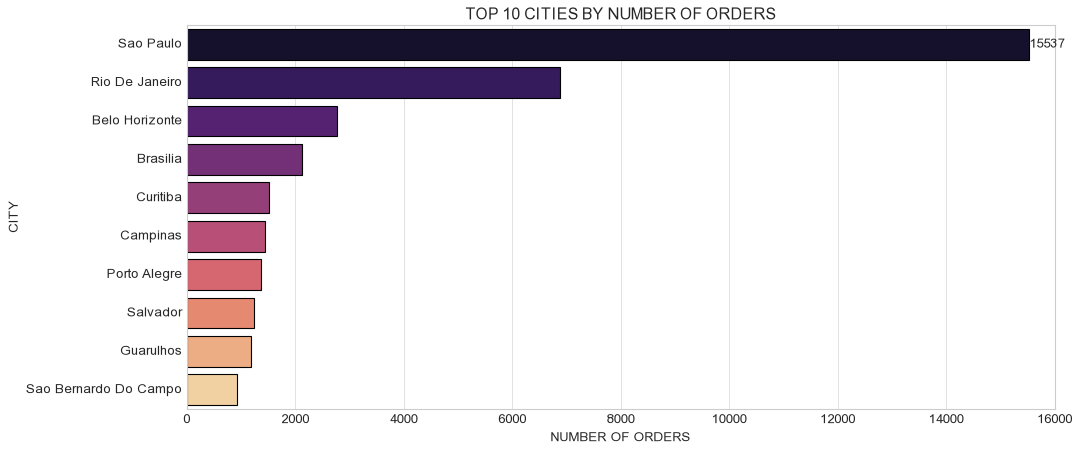

In [278]:
# VISUALIZING THE TOP 10 CUSTOMER CITIES BY NUMBER OF UNIQUE ORDERS WITH THE HELP OF BARPLOT
plt.figure(figsize=(14,6))
top_cities = df.groupby('customer_city')['order_id'].nunique().sort_values(ascending=False).head(10)
print(top_cities)
ax = sns.barplot(x=top_cities.values, y=top_cities.index, palette='magma')
ax.bar_label(ax.containers[0])
plt.title('TOP 10 CITIES BY NUMBER OF ORDERS')
plt.xlabel('NUMBER OF ORDERS')
plt.ylabel('CITY')
plt.show()

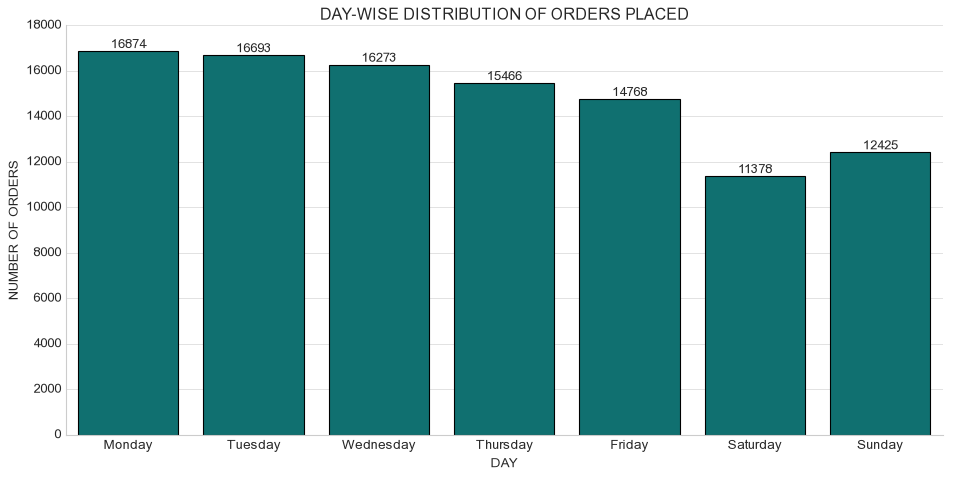

In [279]:
# DAY-WISE DISTRIBUTION OF ORDERS (Monday to Sunday)
day_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
g = sns.catplot(x='day', kind='count', order=day_order, data=df, height=6, aspect=12/6, color='teal')
g.ax.bar_label(g.ax.containers[0])
plt.title('DAY-WISE DISTRIBUTION OF ORDERS PLACED')
plt.xlabel('DAY', fontsize=12)
plt.ylabel('NUMBER OF ORDERS', fontsize=12)
plt.show()

is_late
0    91611
1     7826
Name: count, dtype: int64

Late delivery percentage :  7.87 %


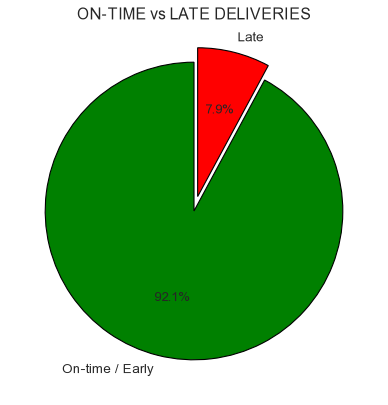

In [280]:
# CALCULATING THE PERCENTAGE OF LATE DELIVERIES AND VISUALIZING IT WITH THE HELP OF PIE CHART
plt.figure(figsize=(6,6))
late_counts = df.drop_duplicates('order_id')['is_late'].value_counts()
print(late_counts)
print("\nLate delivery percentage : ", round(late_counts[1] / late_counts.sum() * 100, 2), "%")
plt.pie(late_counts, labels=['On-time / Early','Late'], autopct='%1.1f%%', colors=['green','red'], startangle=90, explode=[0,0.1])
plt.title('ON-TIME vs LATE DELIVERIES')
plt.show()

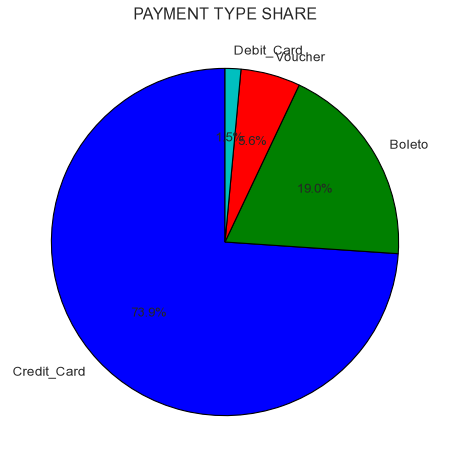

In [281]:
# PAYMENT TYPE SHARE (PIE CHART)
pt = df['payment_type'].value_counts()
plt.figure(figsize=(7,7))
plt.pie(pt, labels=pt.index, autopct='%1.1f%%', startangle=90)
plt.title('PAYMENT TYPE SHARE')
plt.show()

In [282]:
# ORDER STATUS SHARE (in percentage)
(df.drop_duplicates('order_id')['order_status'].value_counts(normalize=True) * 100).round(2)

order_status
Delivered      97.02
Shipped         1.11
Cancelled       0.63
Unavailable     0.61
Invoiced        0.32
Processing      0.30
Created         0.01
Approved        0.00
Name: proportion, dtype: float64

#### 2) BIVARIATE ANALYSIS

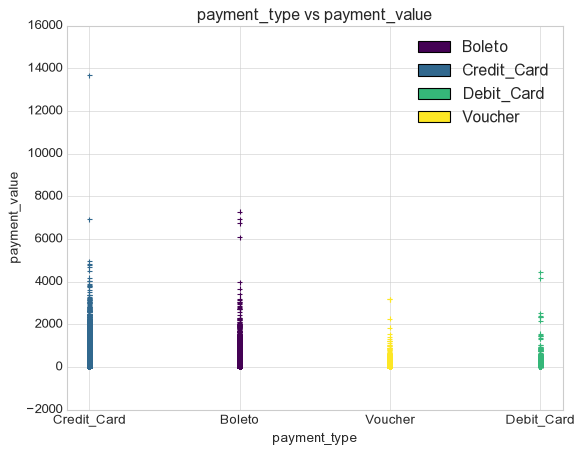

In [283]:
# NUMERICAL VS CATEGORICAL

df.plot(kind = 'scatter',x = 'payment_type',y = 'payment_value',marker = '+',c = 'payment_type',cmap = 'viridis')
plt.title('payment_type vs payment_value')
plt.xlabel('payment_type')
plt.ylabel('payment_value')
plt.show()

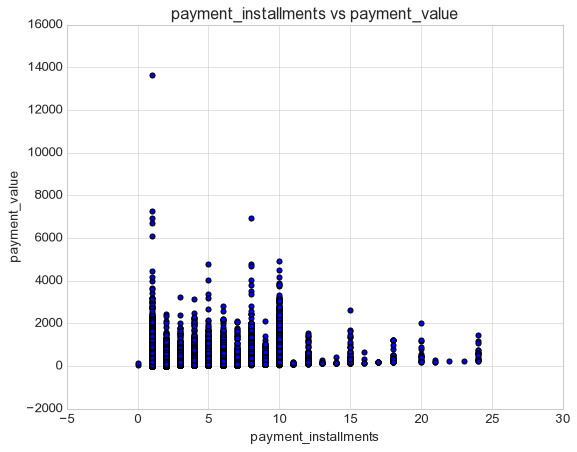

In [284]:
# VISUALIZING THE NUMERICAL VS NUMERICAL COLUMNS RELATIONSHIPS WITH THE HELP OF SCATTER PLOT

df.plot(kind = 'scatter',x = 'payment_installments',y = 'payment_value')
plt.title('payment_installments vs payment_value')
plt.xlabel('payment_installments')
plt.ylabel('payment_value')
plt.show()

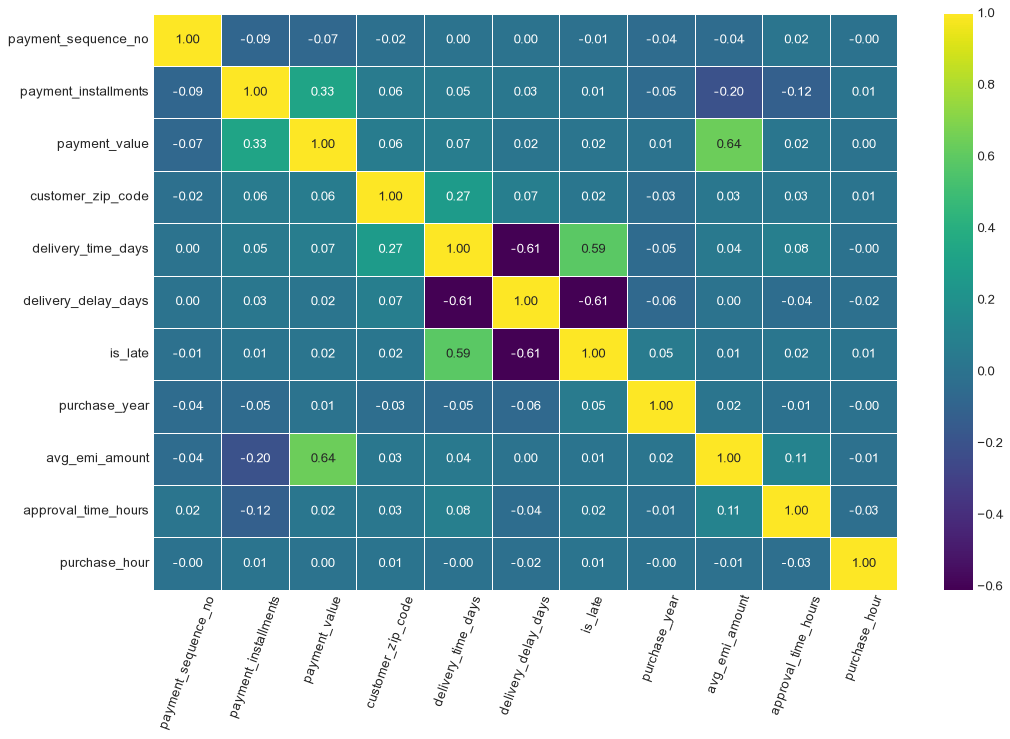

In [285]:
# VISUALIZING THE NUMERICAL VS NUMERICAL COLUMNS RELATIONSHIPS WITH THE HELP OF HEATMAP

q = df[numerical_cols].corr()
plt.figure(figsize = (15,9))
sns.heatmap(data = q,annot=True,cmap = 'viridis', cbar= True,fmt = ".2f",linewidths=0.5)
plt.xticks(rotation = 70)
plt.show()

In [286]:
# CALCULATING THE AVERAGE, MEDIAN AND TOTAL PAYMENT VALUE FOR EACH PAYMENT TYPE
df.groupby('payment_type')['payment_value'].agg(['count','mean','median','max','sum']).round(2).sort_values('sum', ascending=False)

,count,mean,median,max,sum
payment_type,,,,,
Credit_Card,76795,163.32,106.87,13664.08,12542084.19
Boleto,19784,145.03,93.89,7274.88,2869361.27
Voucher,5769,65.77,39.40,3184.34,379436.87
Debit_Card,1529,142.57,89.30,4445.50,217989.79


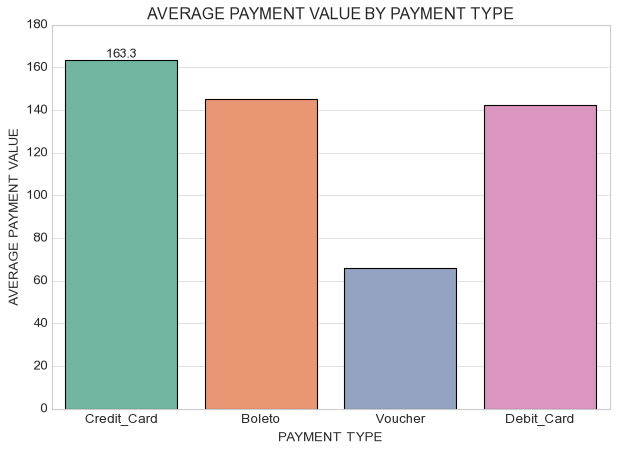

In [287]:
# VIZUALIZING THE AVERAGE PAYMENT VALUE FOR EACH PAYMENT TYPE WITH THE HELP OF BARPLOT
plt.figure(figsize=(9,6))
ax = sns.barplot(data=df, x='payment_type', y='payment_value', estimator='mean', errorbar=None, palette='Set2')
ax.bar_label(ax.containers[0], fmt='%.1f')
plt.title('AVERAGE PAYMENT VALUE BY PAYMENT TYPE')
plt.xlabel('PAYMENT TYPE')
plt.ylabel('AVERAGE PAYMENT VALUE')
plt.show()

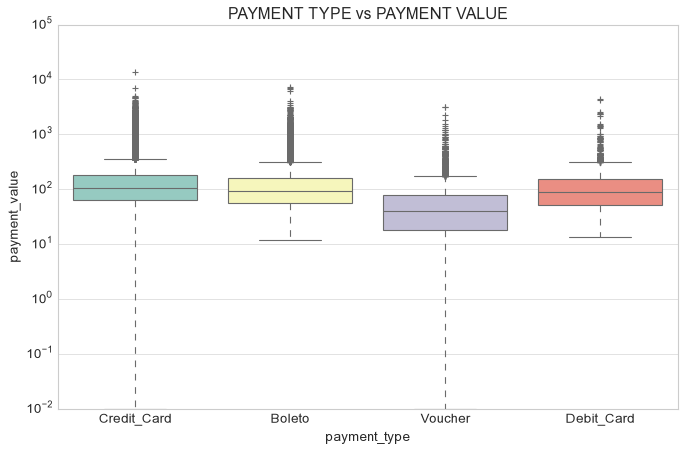

In [288]:
# VISUALIZATION OF PAYMENT TYPE vs PAYMENT VALUE WITH THE HELP OF BOXPLOT (log scale because of heavy right skew)
plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='payment_type', y='payment_value', palette='Set3')
plt.yscale('log')
plt.title('PAYMENT TYPE vs PAYMENT VALUE')
plt.show()

In [289]:
# CALACULATING THE AVERAGE, MEDIAN AND MAXIMUM NUMBER OF INSTALLMENTS FOR EACH PAYMENT TYPE
df.groupby('payment_type')['payment_installments'].agg(['mean','median','max']).round(2)

,mean,median,max
payment_type,,,
Boleto,1.00,1.0,1
Credit_Card,3.51,3.0,24
Debit_Card,1.00,1.0,1
Voucher,1.00,1.0,1


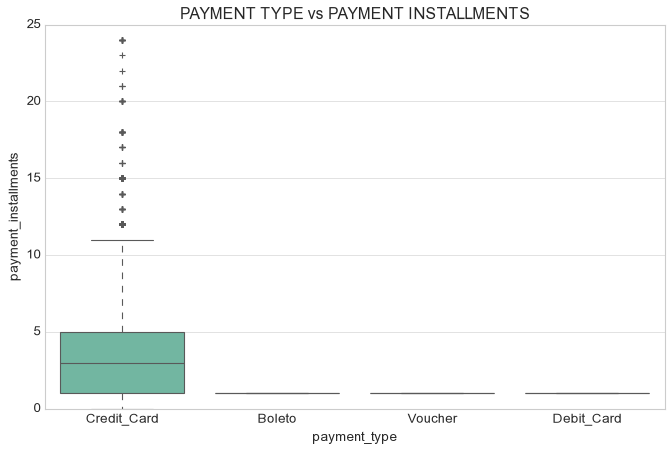

In [290]:
# BOXPLOT FOR VISUALIZING THE PAYMENT TYPE vs PAYMENT INSTALLMENTS
plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='payment_type', y='payment_installments', palette='Set2')
plt.title('PAYMENT TYPE vs PAYMENT INSTALLMENTS')
plt.show()

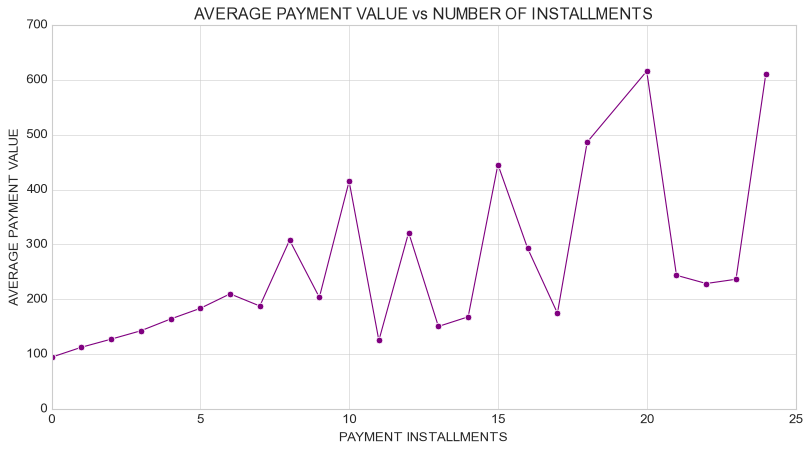

In [291]:
# LINE PLOT FOR VISUALIZING THE AVERAGE PAYMENT VALUE FOR EACH NUMBER OF INSTALLMENTS
plt.figure(figsize=(12,6))
inst = df.groupby('payment_installments')['payment_value'].mean().reset_index()
sns.lineplot(data=inst, x='payment_installments', y='payment_value', marker='o', color='purple')
plt.title('AVERAGE PAYMENT VALUE vs NUMBER OF INSTALLMENTS')
plt.xlabel('PAYMENT INSTALLMENTS')
plt.ylabel('AVERAGE PAYMENT VALUE')
plt.grid(True)
plt.show()

customer_state
RR    28.98
AP    26.65
AM    26.14
AL    24.19
PA    23.28
MA    21.18
SE    20.93
CE    20.69
AC    20.45
PB    19.99
RN    19.20
PI    18.98
RO    18.87
BA    18.79
PE    17.96
MT    17.56
TO    16.87
ES    15.38
MS    15.16
GO    15.12
RJ    14.92
RS    14.78
SC    14.47
DF    12.47
PR    11.57
MG    11.53
SP     8.31
Name: delivery_time_days, dtype: float64


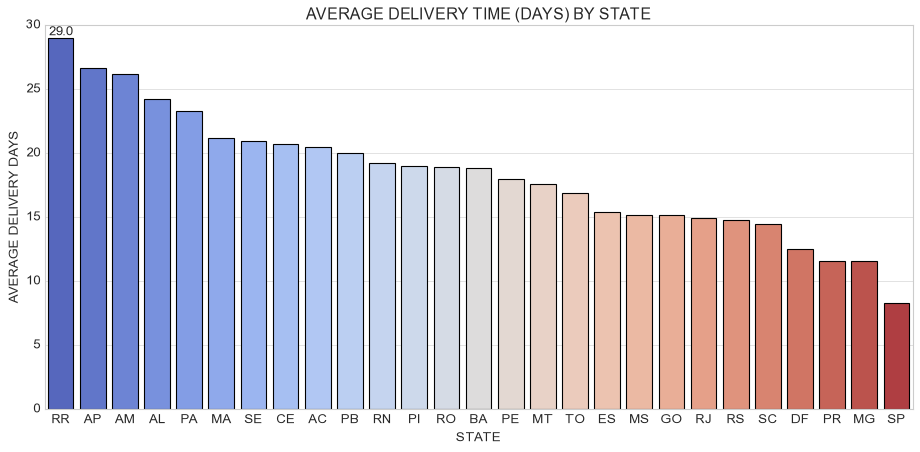

In [292]:
# CALCULATING AND VISUALIZING STATE-WISE AVERAGE DELIVERY TIME (only delivered orders)
plt.figure(figsize=(14,6))
state_delivery = df.groupby('customer_state')['delivery_time_days'].mean().sort_values(ascending=False).round(2)
print(state_delivery)
ax = sns.barplot(x=state_delivery.index, y=state_delivery.values, palette='coolwarm')
ax.bar_label(ax.containers[0], fmt='%.1f')
plt.title('AVERAGE DELIVERY TIME (DAYS) BY STATE')
plt.xlabel('STATE')
plt.ylabel('AVERAGE DELIVERY DAYS')
plt.show()

customer_state
AL    23.00
MA    18.88
PI    15.35
CE    14.67
SE    14.57
BA    13.52
RJ    12.95
TO    12.50
ES    12.00
PA    12.00
Name: is_late, dtype: float64


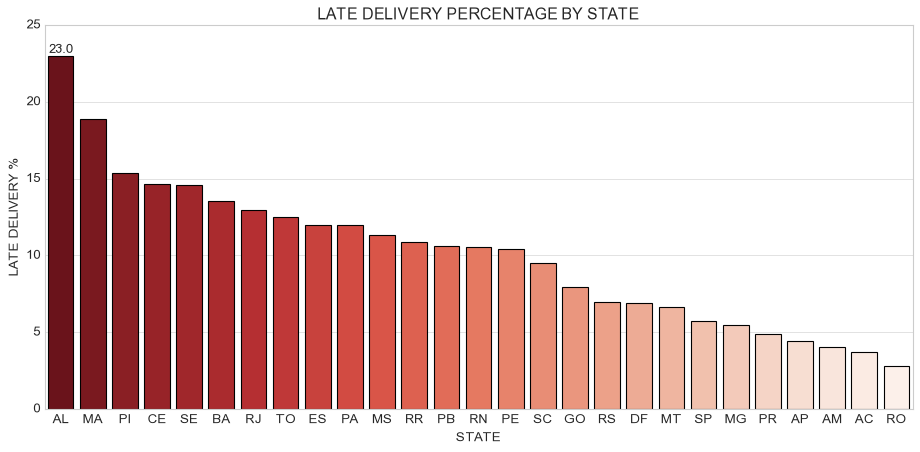

In [293]:
# CALCULATING AND VISUALIZING THE LATE DELIVERY PERCENTAGE FOR EACH STATE (only delivered orders)
plt.figure(figsize=(14,6))
state_late = (df.drop_duplicates('order_id').groupby('customer_state')['is_late'].mean() * 100).sort_values(ascending=False).round(2)
print(state_late.head(10))
ax = sns.barplot(x=state_late.index, y=state_late.values, palette='Reds_r')
ax.bar_label(ax.containers[0], fmt='%.1f')
plt.title('LATE DELIVERY PERCENTAGE BY STATE')
plt.xlabel('STATE')
plt.ylabel('LATE DELIVERY %')
plt.show()

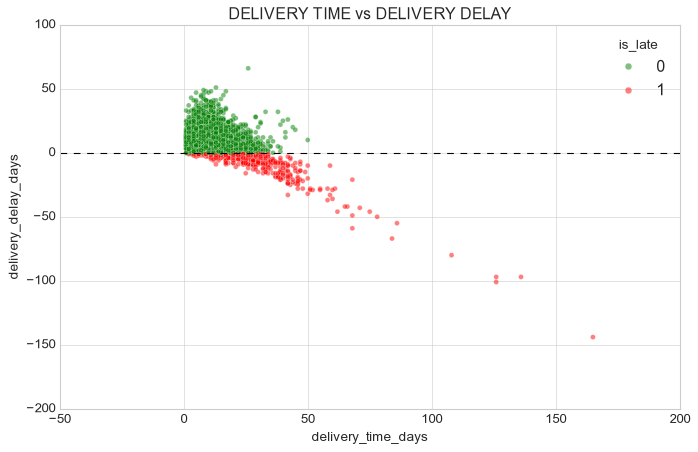

In [294]:
# SCATTER PLOT TO VISUALIZE THE RELATIONSHIP BETWEEN DELIVERY TIME AND DELIVERY DELAY (only delivered orders)
plt.figure(figsize=(10,6))
sns.scatterplot(data=df.sample(5000, random_state=42), x='delivery_time_days', y='delivery_delay_days', hue='is_late', palette={0:'green',1:'red'}, alpha=0.5)
plt.axhline(0, color='black', linestyle='--')
plt.title('DELIVERY TIME vs DELIVERY DELAY')
plt.show()

In [295]:
# CALCULATION OF AVERAGE, MEDIAN AND COUNT OF DELIVERY TIME FOR LATE AND ON-TIME DELIVERIES
df.groupby('is_late')['delivery_time_days'].agg(['count','mean','median']).round(2)

,count,mean,median
is_late,,,
0,92624,10.44,9.0
1,8126,31.12,29.0


month
January       6.04
February     12.95
March        16.56
April         5.80
May           6.47
June          2.17
July          3.96
August        7.37
September     5.02
October       4.84
November     13.83
December      8.14
Name: is_late, dtype: float64


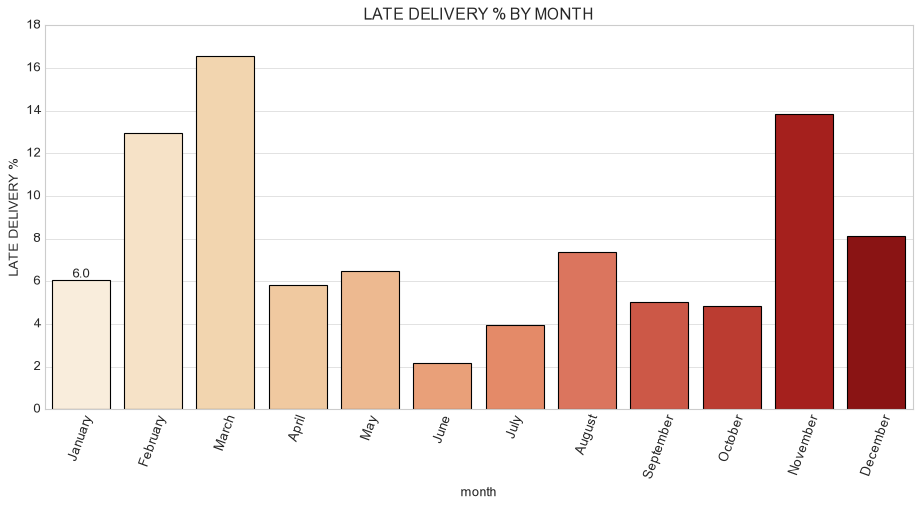

In [296]:
# VISUALIZING AND CALCULATING THE LATE DELIVERY PERCENTAGE FOR EACH MONTH 

plt.figure(figsize=(14,6))
month_order = ['January','February','March','April','May','June','July','August','September','October','November','December']
month_late = (df.drop_duplicates('order_id').groupby('month')['is_late'].mean() * 100).reindex(month_order).round(2)
print(month_late)
ax = sns.barplot(x=month_late.index, y=month_late.values, palette='OrRd')
ax.bar_label(ax.containers[0], fmt='%.1f')
plt.xticks(rotation=70)
plt.title('LATE DELIVERY % BY MONTH')
plt.ylabel('LATE DELIVERY %')
plt.show()

In [297]:
# CALCULATION OF AVERAGE, MEDIAN AND MAX APPROVAL TIME FOR EACH PAYMENT TYPE  
df.groupby('payment_type')['approval_time_hours'].agg(['mean','median','max']).round(2)

,mean,median,max
payment_type,,,
Boleto,33.07,29.04,1450.87
Credit_Card,4.59,0.27,4509.18
Debit_Card,9.54,0.85,676.07
Voucher,8.50,0.28,285.31


#### MULTI-VARIATE ANALYSIS


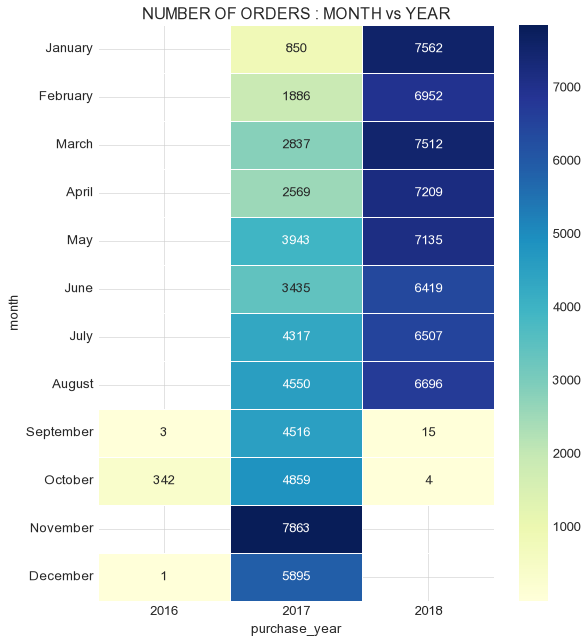

In [298]:
# HEATMAP OF MONTH VS YEAR  -- To visualize the number of orders placed in each month and year
plt.figure(figsize=(8,9))
month_order = ['January','February','March','April','May','June','July','August','September','October','November','December']
pivot = df.pivot_table(index='month', columns='purchase_year', values='order_id', aggfunc='count').reindex(month_order)
sns.heatmap(pivot, annot=True, fmt='.0f', cmap='YlGnBu', linewidths=0.5)
plt.title('NUMBER OF ORDERS : MONTH vs YEAR')
plt.show()

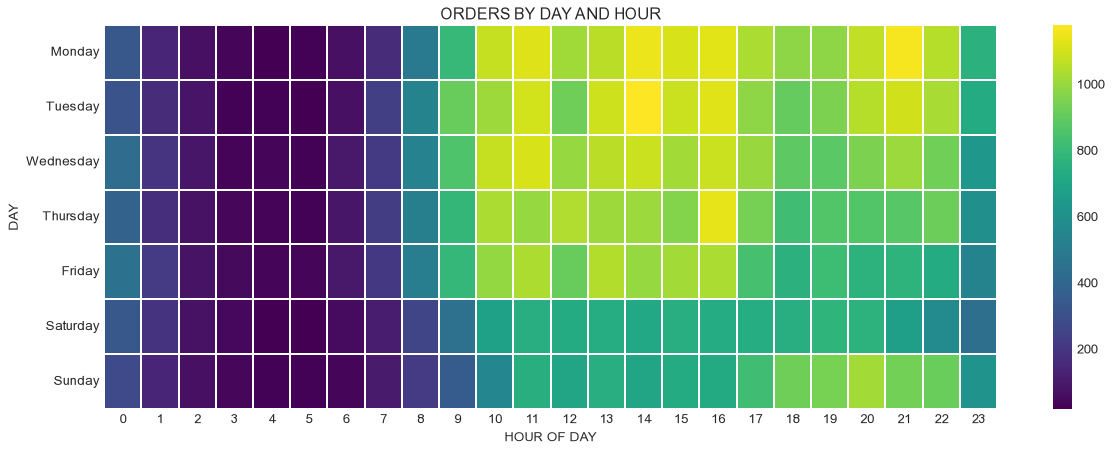

In [299]:
# HEATMAP OF DAY VS HOUR  -- to visualize at which day and hour customers shopping is the most 
plt.figure(figsize=(18,6))
day_order = ['Monday','Tuesday','Wednesday','Thursday','Friday','Saturday','Sunday']
dh = df.pivot_table(index='day',columns='purchase_hour',values='order_id',aggfunc='count').reindex(day_order)
sns.heatmap(dh,cmap='viridis',linewidths=0.3)
plt.title('ORDERS BY DAY AND HOUR')
plt.xlabel('HOUR OF DAY')
plt.ylabel('DAY')
plt.show()

In [300]:
# CORRELATION OF ALL NUMERICAL COLUMNS WITH is_late column ordered by descending order of correlation values
df[numerical_cols].corr()['is_late'].sort_values(ascending=False).round(3)

is_late                 1.000
delivery_time_days      0.589
purchase_year           0.053
customer_zip_code       0.025
approval_time_hours     0.021
payment_value           0.016
payment_installments    0.010
avg_emi_amount          0.009
purchase_hour           0.008
payment_sequence_no    -0.013
delivery_delay_days    -0.605
Name: is_late, dtype: float64

### KPI's of Olist Ecommerce Data

In [301]:
# KIP's
total_revenue=df['payment_value'].sum()
total_orders=df['order_id'].nunique()
total_customers=df['customer_unique_id'].nunique()
aov=total_revenue / total_orders
repeat_cust=(df.groupby('customer_unique_id')['order_id'].nunique() > 1).sum()
cancel_rate=(df['order_status'].isin(['Cancelled','Unavailable']).mean()) * 100
late_rate=df.drop_duplicates('order_id')['is_late'].mean() * 100
print("TOTAL REVENUE (BRL):",round(total_revenue, 2))
print("TOTAL UNIQUE ORDERS:",total_orders)
print("TOTAL UNIQUE CUSTOMERS:",total_customers)
print("AVERAGE ORDER VALUE (BRL):",round(aov, 2))
print("REPEAT CUSTOMERS:",repeat_cust)
print("CANCELLED/UNAVAILABLE RATE %:",round(cancel_rate, 2))
print("LATE DELIVERY RATE %:",round(late_rate, 2))
print("AVERAGE DELIVERY TIME(DAYS):",round(df['delivery_time_days'].mean(), 2))

TOTAL REVENUE (BRL): 16008872.12
TOTAL UNIQUE ORDERS: 99437
TOTAL UNIQUE CUSTOMERS: 96093
AVERAGE ORDER VALUE (BRL): 161.0
REPEAT CUSTOMERS: 2996
CANCELLED/UNAVAILABLE RATE %: 1.26
LATE DELIVERY RATE %: 7.87
AVERAGE DELIVERY TIME(DAYS): 12.11


customer_state
SP    5998226.96
RJ    2144379.69
MG    1872257.26
RS     890898.54
PR     811156.38
SC     623086.43
BA     616645.82
DF     355141.08
GO     350092.31
ES     325967.55
Name: payment_value, dtype: float64


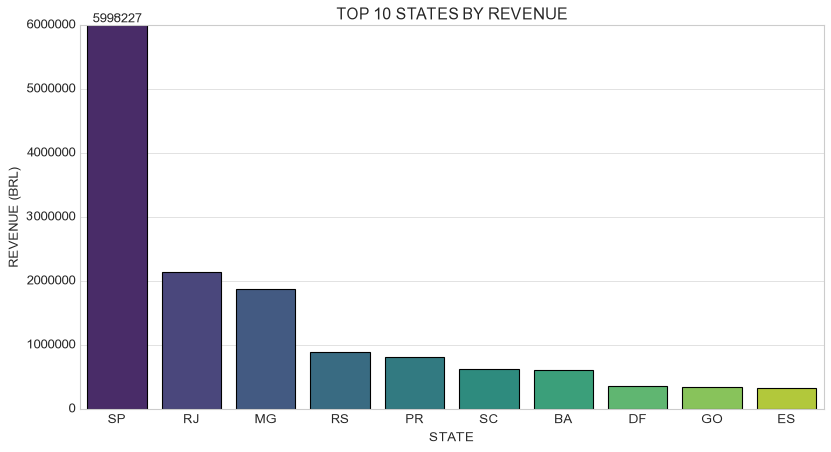

In [302]:
# TOP 10 STATES BY REVENUE
plt.figure(figsize=(12,6))
state_revenue = df.groupby('customer_state')['payment_value'].sum().sort_values(ascending=False).head(10).round(2)
print(state_revenue)
ax = sns.barplot(x=state_revenue.index, y=state_revenue.values, palette='viridis')
ax.bar_label(ax.containers[0], fmt='%.0f')
plt.title('TOP 10 STATES BY REVENUE')
plt.xlabel('STATE')
plt.ylabel('REVENUE (BRL)')
plt.show()

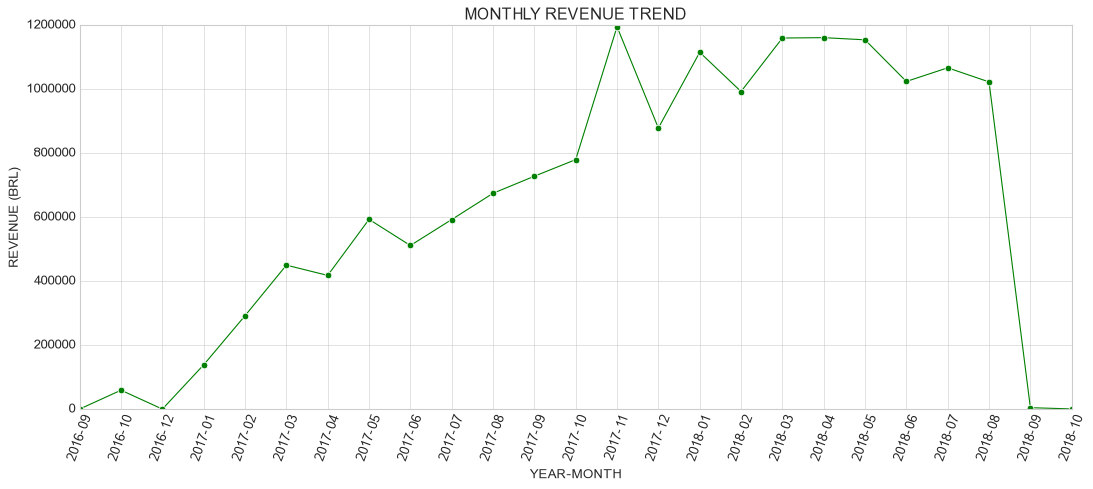

In [303]:
# MONTHLY  TREND of REVENUE (Year-Month wise)
plt.figure(figsize=(16,6))
df['year_month'] = df['order_purchase_timestamp'].dt.to_period('M').astype(str)
monthly_revenue = df.groupby('year_month')['payment_value'].sum().reset_index()
sns.lineplot(data=monthly_revenue, x='year_month', y='payment_value', marker='o', color='green')
plt.xticks(rotation=70)
plt.title('MONTHLY REVENUE TREND')
plt.xlabel('YEAR-MONTH')
plt.ylabel('REVENUE (BRL)')
plt.grid(True)
plt.show()

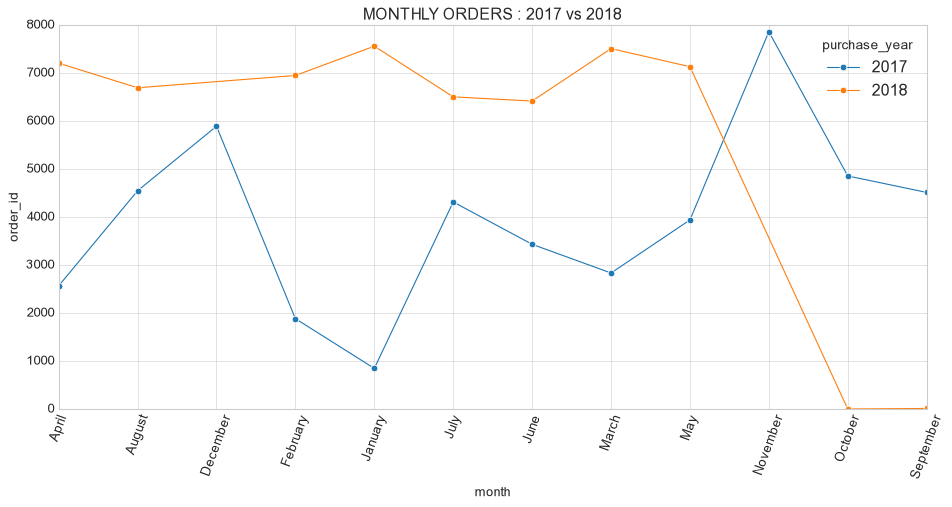

In [304]:
# MONTH WISE ORDERS TREND BY-- YEAR 2017 vs YEAR 2018)
plt.figure(figsize=(14,6))
mo = df[df['purchase_year'].isin([2017, 2018])].groupby(['month','purchase_year'])['order_id'].count().reset_index()
month_order = ['January','February','March','April','May','June','July','August','September','October','November','December']
sns.lineplot(data=mo, x='month', y='order_id', hue='purchase_year', marker='o', palette='tab10')
plt.xticks(rotation=70)
plt.title('MONTHLY ORDERS : 2017 vs 2018')
plt.show()

In [305]:
# YEAR-WISE REVENUE AND AVERAGE ORDER VALUE
df.groupby('purchase_year')['payment_value'].agg(total_revenue='sum', avg_payment='mean', payments='count').round(2)

,total_revenue,avg_payment,payments
purchase_year,,,
2016,59362.34,171.57,346
2017,7249746.73,152.56,47520
2018,8699763.05,155.32,56011


In [306]:
# TOP 10 CUSTOMERS ID BY TOTAL SPENDING
df.groupby('customer_unique_id')['payment_value'].sum().sort_values(ascending=False).head(10).round(2)

customer_unique_id
0a0a92112bd4c708ca5fde585afaa872    13664.08
46450c74a0d8c5ca9395da1daac6c120     9553.02
da122df9eeddfedc1dc1f5349a1a690c     7571.63
763c8b1c9c68a0229c42c9fc6f662b93     7274.88
dc4802a71eae9be1dd28f5d788ceb526     6929.31
459bef486812aa25204be022145caa62     6922.21
ff4159b92c40ebe40454e3e6a7c35ed6     6726.66
4007669dec559734d6f53e029e360987     6081.54
5d0a2980b292d049061542014e8960bf     4809.44
eebb5dda148d3893cdaf5b5ca3040ccb     4764.34
Name: payment_value, dtype: float64

In [307]:
# Number of INSTALLMENT USERS vs ONE-TIME PAYERS
df['payment_mode'] = np.where(df['payment_installments'] > 1, 'Installments', 'One-time')
print(df['payment_mode'].value_counts())
df.groupby('payment_mode')['payment_value'].agg(['count','mean','median']).round(2)

payment_mode
One-time        52539
Installments    51338
Name: count, dtype: int64


,count,mean,median
payment_mode,,,
Installments,51338,196.76,133.57
One-time,52539,112.44,73.34


In [308]:
# Late orders took how many more days
print("Average delivery days (On-time) : ", df[df['is_late']==0]['delivery_time_days'].mean().round(2))
print("Average delivery days (Late)    : ", df[df['is_late']==1]['delivery_time_days'].mean().round(2))
print("Average delay of late orders    : ", abs(df[df['is_late']==1]['delivery_delay_days'].mean()).round(2), "days")

Average delivery days (On-time) :  10.44
Average delivery days (Late)    :  31.12
Average delay of late orders    :  9.92 days


## KEY INSIGHTS

- **The business is growing.** There were very few orders in 2016. In 2017 there were 47,520 payment records, and in 2018 it went up to 56,011.

- **Most orders come from a few states.** Sao Paulo (SP) is far ahead with about 41.7K orders, followed by Rio de Janeiro (RJ) and Minas Gerais (MG). Most of the customers are concentrated in these states.

- **Credit Card is the most popular payment method.** About 74% of the payments are made by Credit Card. It is also the only method where people use installments (about 3.5 on average). All other payment types are paid in one go.

- **Voucher payments are much smaller.** Credit Card, Boleto and Debit Card payments average around 143 to 163 BRL, but Voucher payments average only about 66 BRL.

- **Most orders reach on time.** About 92% of the orders were delivered on time and only 8% were late. The average delivery time is about 12 days.

- **Remote states face long delivery times.** States like RR, AP and AM take 26 to 29 days on average. AL, MA and PI have the highest percentage of late deliveries.

- **Very few customers come back.** Out of about 96K unique customers, only about 3K ordered more than once (around 3%). The business should work on bringing customers back.

In [309]:
df.to_csv('Brazillian_olist_final_eda_dataset.csv', index=False)
print("Final dataset saved successfully with shape : ", df.shape)

Final dataset saved successfully with shape :  (103877, 27)
